# Module 4：用真实图片训练一个 CNN

这是围绕官方讲义第一组 CNN 视频编写的本地练习。我们使用已经下载的 MNIST 手写数字，继续沿用上一题的 8、16 个卷积输出通道；数据与讲义中的 15 类自然图片示例不同。

本次只做一件事：把刚才已经写对的 CNN 接上真实图片，训练一轮。你自己完成模型，数据读取、训练和画图代码已提供。

用 VS Code 打开本文件，选择 PyTorch 学习环境 `.venv`。从上向下运行，遇到“请完成 CNN 模型”就停下来填写该单元。当前已有 CUDA 版 PyTorch，本练习没有安装命令，也不需要 helper_utils.py。


In [1]:
from pathlib import Path
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('本次计算设备：', device)
if device.type == 'cuda':
    print('显卡：', torch.cuda.get_device_name(0))


本次计算设备： cuda
显卡： NVIDIA GeForce RTX 5070 Laptop GPU


## 1. 沿用 Module 2 的数据

下面的路径已经按你当前 E 盘的位置设置。`download=False` 表示只读取已有数据。如果以后移动了文件夹，修改 `DATA_DIR` 即可。

MNIST 是 **28×28 的单通道灰度图片，标签是 0～9**。图片经 `ToTensor()` 和标准化后，再按批送给模型。

从原来的 60,000 张训练图片中，固定划分 50,000 张训练、10,000 张验证。这里只使用确定的预处理，所以训练集和验证集可以共享这个底层 Dataset。官方另外提供的 10,000 张测试图片本次先保留。


In [2]:
DATA_DIR = Path(r'E:\Study\My_Project\PyTorch-study\module2\data')
print('读取数据的位置：', DATA_DIR)

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

base_dataset = datasets.MNIST(
    root=str(DATA_DIR), train=True, download=False, transform=transform
)
train_dataset, val_dataset = random_split(
    base_dataset, [50000, 10000],
    generator=torch.Generator().manual_seed(42)
)

train_loader = DataLoader(
    train_dataset, batch_size=64, shuffle=True, num_workers=0,
    generator=torch.Generator().manual_seed(42)
)
val_loader = DataLoader(
    val_dataset, batch_size=256, shuffle=False, num_workers=0
)

images, labels = next(iter(val_loader))
print('训练图片数：', len(train_dataset))
print('验证图片数：', len(val_dataset))
print('一批真实图片的形状：', images.shape)
print('对应标签的形状：', labels.shape)
print('前八张图片的正确标签：', labels[:8])


读取数据的位置： E:\Study\My_Project\PyTorch-study\module2\data
训练图片数： 50000
验证图片数： 10000
一批真实图片的形状： torch.Size([256, 1, 28, 28])
对应标签的形状： torch.Size([256])
前八张图片的正确标签： tensor([4, 5, 2, 8, 4, 5, 3, 2])


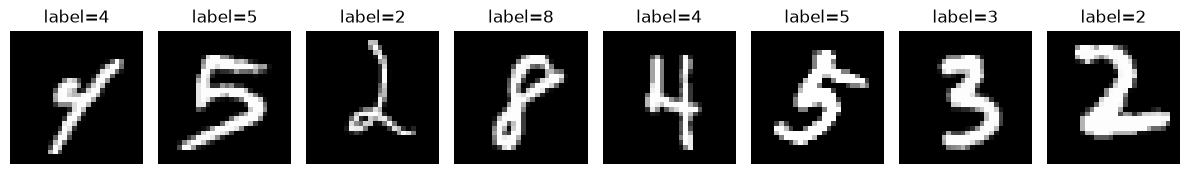

256 256


In [ ]:
# 与 Module 2 的显示方法相同：还原标准化，再画出前八张。
fig, axes = plt.subplots(1, 8, figsize=(12, 2))
for i, ax in enumerate(axes):
    ax.imshow(images[i, 0] * 0.3081 + 0.1307, cmap='gray', vmin=0, vmax=1)
    ax.set_title(f'label={labels[i].item()}')
    ax.axis('off')
plt.tight_layout()
plt.show()


## 2. 你来完成 CNN

沿用你刚才写的 `nn.Sequential`，变量仍命名为 `model`，顺序仍是：

```text
Conv2d → ReLU → MaxPool2d → Conv2d → ReLU → MaxPool2d → Flatten → Linear
```

- 第一层卷积输出 8 个通道，第二层输出 16 个通道。
- 两个卷积都使用 `kernel_size=3, stride=1, padding=1`。
- 两个池化都使用 `kernel_size=2, stride=2`。
- `Flatten()` 保留批大小。
- 最后的 `Linear` 给每个数字类别输出一个分数，不加 Softmax。
- 创建模型后，使用 `.to(device)` 将它放到选定设备上。

相比上一题，要根据真实图片调整三个参数：**第一层的输入通道数、Linear 的输入数量、Linear 的输出数量**。28×28 的图片经过两次池化会变成多大？用这个结果确定展平后的数量。

把下面的 `raise` 整行替换成自己的模型代码。开头的随机种子保留，方便从头运行时比较结果。


In [8]:
torch.manual_seed(42)

# TODO：在这里定义 model = nn.Sequential(...).to(device)
model = nn.Sequential(
    nn.Conv2d(1, 8, kernel_size=3, stride=1, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2, stride=2),
    nn.Conv2d(8, 16, kernel_size=3, stride=1, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2, stride=2),
    nn.Flatten(),
    nn.Linear(16 * 7 * 7, 10)
).to(device)

print(model)


Sequential(
  (0): Conv2d(1, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU()
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(8, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (4): ReLU()
  (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (6): Flatten(start_dim=1, end_dim=-1)
  (7): Linear(in_features=784, out_features=10, bias=True)
)


下面会让一批真实图片依次经过各层，并打印形状。`for layer in model` 表示按顺序取出 `Sequential` 中的每一层。

这一步使用 `no_grad()`，只检查前向计算。最后应得到 `[这批图片的数量, 10]`。


In [9]:
model.eval()
with torch.no_grad():
    features = images.to(device)
    print('输入：', features.shape)
    for layer in model:
        features = layer(features)
        print(layer, '→', features.shape)

assert tuple(features.shape) == (len(images), 10)
parameter_count = sum(p.numel() for p in model.parameters())
print('可训练参数数量：', parameter_count)
print('形状检查通过，可以开始训练。')


输入： torch.Size([256, 1, 28, 28])
Conv2d(1, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1)) → torch.Size([256, 8, 28, 28])
ReLU() → torch.Size([256, 8, 28, 28])
MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False) → torch.Size([256, 8, 14, 14])
Conv2d(8, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1)) → torch.Size([256, 16, 14, 14])
ReLU() → torch.Size([256, 16, 14, 14])
MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False) → torch.Size([256, 16, 7, 7])
Flatten(start_dim=1, end_dim=-1) → torch.Size([256, 784])
Linear(in_features=784, out_features=10, bias=True) → torch.Size([256, 10])
可训练参数数量： 9098
形状检查通过，可以开始训练。


## 3. 训练流程与 Module 2 相同

CNN 改变了模型内部处理图片的方法，但每批数据的训练仍然是你已经写过的五步：

```text
清空梯度 → 前向预测 → 计算损失 → 反向传播 → 更新参数
```

`train_one_epoch()` 返回这一轮的平均损失和准确率。`evaluate()` 只做评估，不更新参数。下面两个函数已完整提供，可以直接运行；重点看五步训练代码仍然没有变化。


In [10]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    total_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        # 仍然是熟悉的五步训练。
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        batch_size = labels.size(0)
        total_loss += loss.item() * batch_size
        predicted = outputs.detach().argmax(dim=1)
        correct += (predicted == labels).sum().item()
        total += batch_size

    return total_loss / total, correct / total


In [11]:
def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)

            batch_size = labels.size(0)
            total_loss += loss.item() * batch_size
            predicted = outputs.argmax(dim=1)
            correct += (predicted == labels).sum().item()
            total += batch_size

    return total_loss / total, correct / total


先训练 **1 轮**，走通流程。这次创建的是新 CNN，因此优化器也要重新创建，让它管理这个模型的参数。

同一个训练单元再运行一次，会接着训练当前模型。想从头重做，应先重新运行模型单元，再重新创建优化器，然后训练。

输出中的 `.4f` 表示保留四位小数；`.2%` 表示转换为百分数并保留两位小数。验证准确率没有固定标准答案。


In [12]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)


In [16]:
epochs = 9
history = []
for epoch in range(epochs):
    train_loss, train_accuracy = train_one_epoch(
        model, train_loader, criterion, optimizer, device
    )
    val_loss, val_accuracy = evaluate(model, val_loader, criterion, device)
    history.append((train_loss, train_accuracy, val_loss, val_accuracy))
    print(f'Epoch {epoch + 1}/{epochs}')
    print(f'训练 loss={train_loss:.4f} | 训练 accuracy={train_accuracy:.2%}')
    print(f'验证 loss={val_loss:.4f} | 验证 accuracy={val_accuracy:.2%}')


Epoch 1/9
训练 loss=0.0837 | 训练 accuracy=97.44%
验证 loss=0.0759 | 验证 accuracy=97.76%
Epoch 2/9
训练 loss=0.0606 | 训练 accuracy=98.07%
验证 loss=0.0739 | 验证 accuracy=97.73%
Epoch 3/9
训练 loss=0.0513 | 训练 accuracy=98.43%
验证 loss=0.0591 | 验证 accuracy=98.31%
Epoch 4/9
训练 loss=0.0445 | 训练 accuracy=98.61%
验证 loss=0.0610 | 验证 accuracy=98.09%
Epoch 5/9
训练 loss=0.0381 | 训练 accuracy=98.83%
验证 loss=0.0566 | 验证 accuracy=98.35%
Epoch 6/9
训练 loss=0.0347 | 训练 accuracy=98.91%
验证 loss=0.0548 | 验证 accuracy=98.38%
Epoch 7/9
训练 loss=0.0311 | 训练 accuracy=98.98%
验证 loss=0.0519 | 验证 accuracy=98.46%
Epoch 8/9
训练 loss=0.0270 | 训练 accuracy=99.16%
验证 loss=0.0671 | 验证 accuracy=98.15%
Epoch 9/9
训练 loss=0.0243 | 训练 accuracy=99.20%
验证 loss=0.0571 | 验证 accuracy=98.25%


## 4. 看看真实图片的预测

下面只显示验证集的前十二张。`true` 是正确标签，`pred` 是模型预测；绿色表示预测正确，红色表示预测错误。整体验证准确率已经用全部 10,000 张验证图片计算过，不能只凭这十二张判断模型表现。


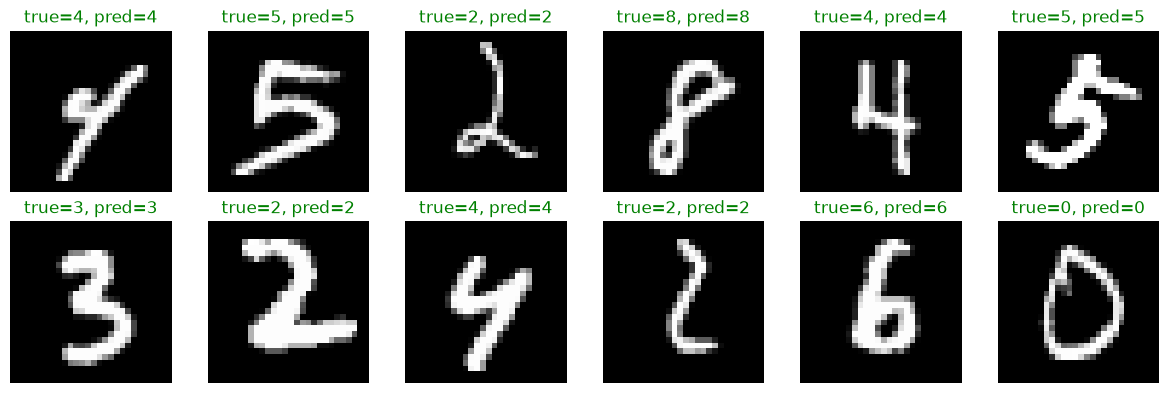

In [17]:
model.eval()
val_images, val_labels = next(iter(val_loader))
with torch.no_grad():
    predictions = model(val_images[:12].to(device)).argmax(dim=1).cpu()

fig, axes = plt.subplots(2, 6, figsize=(12, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(val_images[i, 0] * 0.3081 + 0.1307, cmap='gray', vmin=0, vmax=1)
    good = predictions[i].item() == val_labels[i].item()
    ax.set_title(f'true={val_labels[i].item()}, pred={predictions[i].item()}',
                 color='green' if good else 'red')
    ax.axis('off')
plt.tight_layout()
plt.show()


本次把 **CNN 模型代码** 和 **一轮训练后的训练、验证结果** 一起发来即可，不需要逐个单元提交。

这次练习让你确认：换成 CNN 后，图片可以在展平之前先经过卷积和池化，而损失函数、优化器和五步训练流程仍然可以沿用。


第一层特征图形状： torch.Size([1, 8, 28, 28])


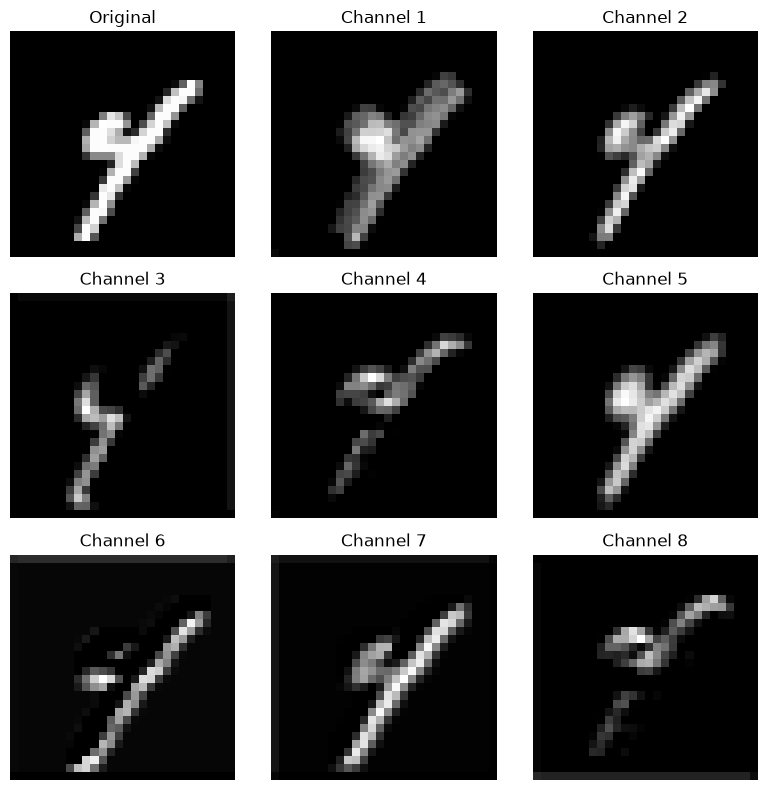

In [19]:
model.eval()

with torch.no_grad():
    one_image = val_images[:1].to(device)

    conv_output = model[0](one_image)          # 第一层卷积
    feature_maps = model[1](conv_output).cpu() # 接着经过 ReLU

print("第一层特征图形状：", feature_maps.shape)

fig, axes = plt.subplots(3, 3, figsize=(8, 8))

for i, ax in enumerate(axes.flat):
    if i == 0:
        original = val_images[0, 0] * 0.3081 + 0.1307
        ax.imshow(original, cmap="gray", vmin=0, vmax=1)
        ax.set_title("Original")
    else:
        ax.imshow(feature_maps[0, i - 1], cmap="gray", vmin=0)
        ax.set_title(f"Channel {i}")

    ax.axis("off")

plt.tight_layout()
plt.show()